# 🚀 Spaceships — tiny, deterministic, auditable inference for flight hardware

Aerospace doesn't just want *fast* — it wants **bounded, predictable, and readable**. A flight computer has little memory, no room for a heavyweight ML runtime, and a hard requirement that every operation finish inside its time budget — *every single time*, worst case included. And anything safety-critical has to be **auditable**: you must be able to read and reason about the code that's flying.

Rapid Lightning fits that brief almost suspiciously well. The whole model compiles to **~15 KB of straight-line C** — no heap allocation, no library beyond `expf`, no data-dependent loops — so its latency is **tiny *and* repeatable** (a real worst-case bound, not just a good average), and you can read the entire predictor.

This notebook frames it as **onboard sensor health-monitoring**: classify a multi-channel telemetry vector as nominal or anomalous, at the sample rates real instrumentation runs. *Every number is computed live.*

In [1]:
import time, numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt
%matplotlib inline
from rapidlightning import RapidLightningClassifier
import xgboost as xgb
print("ready.")

ready.


## 1 · The task — onboard telemetry health monitoring

A 12-channel sensor vector (think pressures, temperatures, vibrations, currents). Anomalies are **rare** (~5%), as real faults are — so we watch PR-AUC, not just accuracy.

In [2]:
X, y = make_classification(n_samples=6000, n_features=12, n_informative=8, n_redundant=2,
                           n_clusters_per_class=2, weights=[0.95, 0.05], class_sep=1.1,
                           flip_y=0.01, random_state=7)
Xtr, Xte, ytr, yte = train_test_split(X.astype(np.float32), y.astype(np.int64),
                                      test_size=3000, random_state=7, stratify=y)
sc = StandardScaler().fit(Xtr)
Xtr, Xte = sc.transform(Xtr).astype(np.float32), sc.transform(Xte).astype(np.float32)
print(f"sensor channels = {Xtr.shape[1]}   train = {len(Xtr)}   anomaly rate = {ytr.mean():.1%}")

sensor channels = 12   train = 3000   anomaly rate = 5.5%


## 2 · Same detection quality as XGBoost

In [3]:
clf = RapidLightningClassifier(n_members=10, generations=20, population=160, seed=3).fit(Xtr, ytr)
rl_p = clf.predict_proba(Xte)[:, 1]
xf = xgb.XGBClassifier(n_estimators=300, max_depth=6, random_state=7, verbosity=0).fit(Xtr, ytr)
xf_p = xf.predict_proba(Xte)[:, 1]
print(f"{'model':<18}{'ROC-AUC':>9}{'PR-AUC':>9}")
print(f"{'Rapid Lightning':<18}{roc_auc_score(yte,rl_p):>9.4f}{average_precision_score(yte,rl_p):>9.4f}")
print(f"{'XGBoost':<18}{roc_auc_score(yte,xf_p):>9.4f}{average_precision_score(yte,xf_p):>9.4f}")

fast = clf.compile()
c_auc = roc_auc_score(yte[:3000], fast.predict_proba(Xte[:3000]))
print(f"\ncompiled: {fast.size_kb:.1f} KB   faithful C-AUC {c_auc:.4f}")

model               ROC-AUC   PR-AUC
Rapid Lightning      0.9041   0.6675
XGBoost              0.8971   0.6886

compiled: 15.4 KB   faithful C-AUC 0.9041


## 3 · The flight-grade artifact: 15 KB you can *read*

The deployable model is the C below — every channel reference, every operation, in the open. **No heap, no dependencies beyond `expf`, no data-dependent loops.** That's what makes it analyzable: a reviewer can audit it, and a tool can bound its worst-case execution time. Compare that to shipping a tree-ensemble runtime as an opaque dependency.

In [4]:
print(f"deployable artifact: predict.so  ({fast.size_kb:.1f} KB, zero dependencies)")
print(f"that footprint fits the flash of a rad-hard microcontroller with room to spare.\n")
print("--- predict.c (the entire model, head) ---")
print("\n".join(fast.c_source.splitlines()[:8]))
print("   ... (one line per GP tree, then the logistic head and a sigmoid)")

deployable artifact: predict.so  (15.4 KB, zero dependencies)
that footprint fits the flash of a rad-hard microcontroller with room to spare.

--- predict.c (the entire model, head) ---
#include <math.h>
#include <time.h>

float predict_proba_one(const float* X){
    float f0 = (float)(((fabsf(X[8])*(fminf(X[1],fmaxf(X[4],X[8]))-X[1]))+((fabsf(X[1])*(fminf(X[1],fmaxf(X[4],X[4]))-X[1]))-fabsf((-1.26704923f)))));
    float f1 = (float)(fmaxf(fminf((-1.56296527f),X[1]),(((X[1]+(((X[1]+X[11])+(-1.59360603f))+(-0.863731941f)))+(-0.948838601f))+(-0.863731941f))));
    float f2 = (float)((((fmaxf(((-(X[2]))+fminf((X[5]*(0.394572984f)),(1.66357634f))),((X[11]<((X[11]<fminf(fmaxf(X[8],0.0f),1.0f))?1.0f:0.0f))?1.0f:0.0f))<(fminf(fmaxf(fabsf((fminf(X[7],(-0.510345086f))-X[0])),0.0f),1.0f)-(-(((X[5]*(0.394572984f))*(0.394572984f))))))?1.0f:0.0f)*fabsf(X[0])));
    float f3 = (float)((-(fabsf((X[5]*(fminf(fmaxf(X[5],0.0f),1.0f)*fminf(fmaxf(((X[4]<(-0.649685561f))?1.0f:0.0f),0.0f),1.0f)))))));
   ..

## 4 · Deterministic latency — a real worst case, not just a good average

Hard-real-time systems are judged by their **worst case**, not their mean. Rapid Lightning's compiled inference runs the same straight-line path every time, so its latency is tightly bounded and repeatable. A tree-ensemble called through a Python runtime carries that runtime's overhead *and* a heavy, unpredictable tail (allocation, garbage collection, branch-per-node). We measure both the way each is actually deployed.

Rapid Lightning .so  : mean   38.6 ns   worst-of-15-runs   41.2 ns   (spread 0.83 ns)
XGBoost (Python)     : p50  330,552 ns   p99 1,351,216 ns   max 24,743,531 ns
  -> XGBoost-Python's tail is 4.1x its median; RL's worst case sits ~41 ns, period.


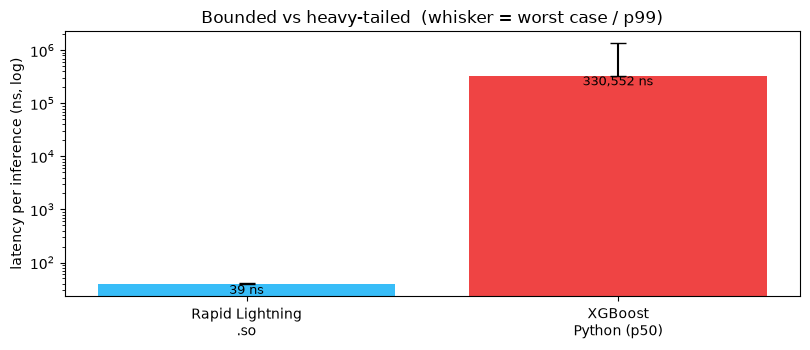

In [5]:
rl_runs = np.array([fast.benchmark_ns(x=Xte[0], n_warmup=2000, n_iters=200000) for _ in range(15)])
lat = np.empty(4000)
for i in range(4000):
    j = i % len(Xte); t0 = time.perf_counter_ns(); xf.predict_proba(Xte[j:j+1]); lat[i] = time.perf_counter_ns()-t0
rl_ns, rl_max = rl_runs.mean(), rl_runs.max()
xg_p50, xg_p99, xg_max = np.percentile(lat,50), np.percentile(lat,99), lat.max()
print(f"Rapid Lightning .so  : mean {rl_ns:6.1f} ns   worst-of-15-runs {rl_max:6.1f} ns   (spread {rl_runs.std():.2f} ns)")
print(f"XGBoost (Python)     : p50 {xg_p50:8,.0f} ns   p99 {xg_p99:8,.0f} ns   max {xg_max:8,.0f} ns")
print(f"  -> XGBoost-Python's tail is {xg_p99/xg_p50:.1f}x its median; RL's worst case sits ~{rl_max:.0f} ns, period.")

fig, ax = plt.subplots(figsize=(8.2, 3.6))
ax.bar(['Rapid Lightning\n.so', 'XGBoost\nPython (p50)'], [rl_ns, xg_p50],
       yerr=[[0,0],[rl_max-rl_ns, xg_p99-xg_p50]], color=['#38bdf8','#ef4444'], capsize=6)
ax.set_yscale('log'); ax.set_ylabel('latency per inference (ns, log)')
ax.set_title('Bounded vs heavy-tailed  (whisker = worst case / p99)')
for i,(lo,hi) in enumerate([(rl_ns,rl_max),(xg_p50,xg_max)]):
    ax.text(i, lo, f'{lo:,.0f} ns', ha='center', va='top', fontsize=9)
plt.tight_layout(); plt.show()

## 5 · Keeping up at aerospace sensor rates — where heavy predictors fall off

Instrumentation samples *fast* — IMUs at kHz, vibration and structural monitoring into the tens of kHz. At those rates the per-sample time budget shrinks below what a Python-served tree ensemble can deliver, and it simply can't run in the loop. Rapid Lightning stays in the noise.

 sample rate   budget/sample     RL load    XGBoost-Python
       1 kHz    1,000,000 ns      0.004%     33% of budget
      10 kHz      100,000 ns      0.039%     can't keep up
      50 kHz       20,000 ns      0.193%     can't keep up
     200 kHz        5,000 ns      0.772%     can't keep up

max sustainable rate (1/latency):  Rapid Lightning ~26 MHz   |   XGBoost-Python ~3.0 kHz


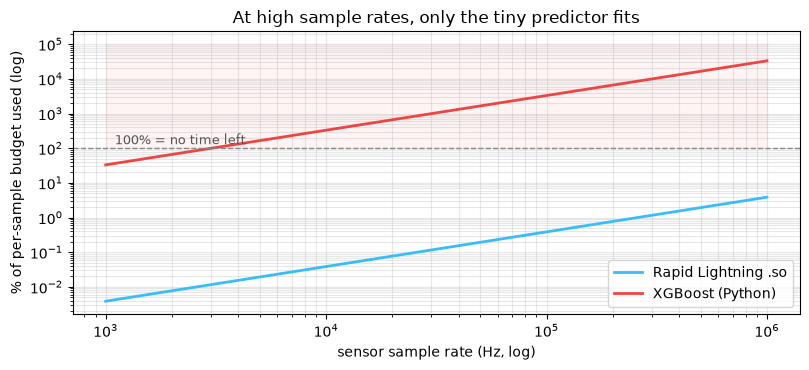

In [6]:
rates = [1e3, 1e4, 5e4, 2e5]; labels = ['1 kHz','10 kHz','50 kHz','200 kHz']
print(f"{'sample rate':>12}{'budget/sample':>16}{'RL load':>12}{'XGBoost-Python':>18}")
rl_load, feasible = [], []
for hz in rates:
    budget = 1e9/hz
    rl_load.append(rl_ns/budget*100)
    ok = xg_p50 < budget; feasible.append(ok)
    xg = f"{xg_p50/budget*100:.0f}% of budget" if ok else "can't keep up"
    print(f"{labels[rates.index(hz)]:>12}{budget:>13,.0f} ns{rl_ns/budget*100:>11.3f}%{xg:>18}")
print(f"\nmax sustainable rate (1/latency):  Rapid Lightning ~{1e9/rl_ns/1e6:.0f} MHz   |   XGBoost-Python ~{1e9/xg_p50/1e3:.1f} kHz")

fig, ax = plt.subplots(figsize=(8.2, 3.8))
hz = np.logspace(3, 6, 100); ax.plot(hz, rl_ns/(1e9/hz)*100, color='#38bdf8', lw=2, label='Rapid Lightning .so')
ax.plot(hz, xg_p50/(1e9/hz)*100, color='#ef4444', lw=2, label='XGBoost (Python)')
ax.axhline(100, color='#888', ls='--', lw=1); ax.text(1.1e3, 130, '100% = no time left', color='#555', fontsize=9)
ax.fill_between(hz, 100, 1e5, color='#ef4444', alpha=0.06)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('sensor sample rate (Hz, log)')
ax.set_ylabel('% of per-sample budget used (log)'); ax.set_title('At high sample rates, only the tiny predictor fits')
ax.legend(); ax.grid(alpha=.3, which='both'); plt.tight_layout(); plt.show()

## What you just saw

- **Same detection quality** as XGBoost on rare-anomaly telemetry.
- **A 15 KB artifact you can read** — straight-line C, no heap, no runtime dependency — the kind of thing you can audit and fit on constrained flight hardware.
- **A real worst case, not just a good average:** Rapid Lightning's latency is bounded and repeatable; a Python-served ensemble carries a heavy, unpredictable tail.
- **It keeps up where others can't:** at tens-of-kHz sensor rates, the heavyweight predictor runs out of budget; Rapid Lightning is still idle.

Fast, tiny, bounded, and legible — the combination that lets a learned model fly where, until now, only hand-written code could go.

---

*That's the trio — 🛰️ Sensors, 🤖 Droids, 🚀 Spaceships — all on one ~15 KB, dependency-free core you can lift into any project that uses XGBoost.*